### Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

### Memuat tabel perbandingan

In [2]:
df_perbandingan = joblib.load('df_perbandingan.pkl')
print("Data perbandingan regresi berhasil dimuat!")
display(df_perbandingan)

Data perbandingan regresi berhasil dimuat!


,Model,R2 Score,R2 (%),MAE,RMSE,MAPE (%),Waktu Eksekusi (Detik)
0,KNN,0.635518,63.55,5.924703e+08,7.908808e+08,143.50,0.064623
1,Random Forest,0.747389,74.74,4.642134e+08,6.584145e+08,149.70,2.428296
2,SVM,0.663929,66.39,5.565388e+08,7.594314e+08,183.97,1.307720


### Visualisasi Perbandingan R2 Score (%) per Model

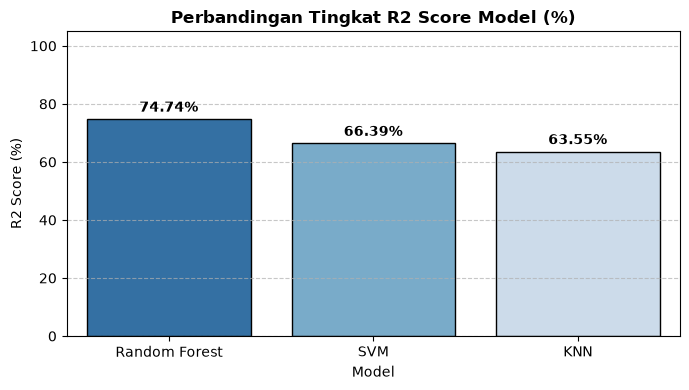

In [4]:
df_urut_r2 = df_perbandingan.sort_values(by='R2 (%)', ascending=False)

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    data=df_urut_r2, x='Model', y='R2 (%)', 
    hue='Model', palette='Blues_r', edgecolor='black', legend=False
)

plt.title('Perbandingan Tingkat R2 Score Model (%)', fontsize=12, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('R2 Score (%)')
plt.ylim(0, 105)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

### Visualisasi Perbandingan MAE (Rupiah) per Model

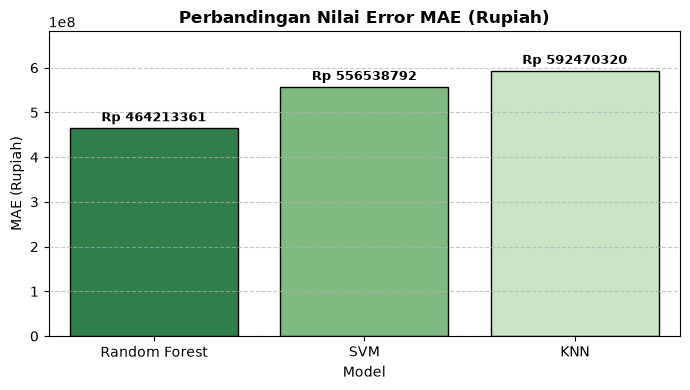

In [6]:
df_urut_mae = df_perbandingan.sort_values(by='MAE', ascending=True)

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    data=df_urut_mae, x='Model', y='MAE', 
    hue='Model', palette='Greens_r', edgecolor='black', legend=False
)

plt.title('Perbandingan Nilai Error MAE (Rupiah)', fontsize=12, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('MAE (Rupiah)')
plt.ylim(0, df_urut_mae['MAE'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt='Rp %.0f', padding=3, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Visualisasi Perbandingan RMSE (Rupiah) per Model

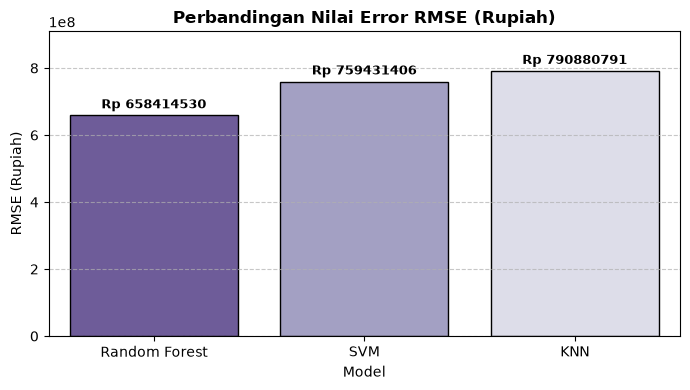

In [10]:
df_urut_rmse = df_perbandingan.sort_values(by='RMSE', ascending=True)

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    data=df_urut_rmse, x='Model', y='RMSE', 
    hue='Model', palette='Purples_r', edgecolor='black', legend=False
)

plt.title('Perbandingan Nilai Error RMSE (Rupiah)', fontsize=12, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('RMSE (Rupiah)')
plt.ylim(0, df_urut_rmse['RMSE'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='Rp %.0f', padding=3, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Visualisasi Perbandingan MAPE (%) per Model

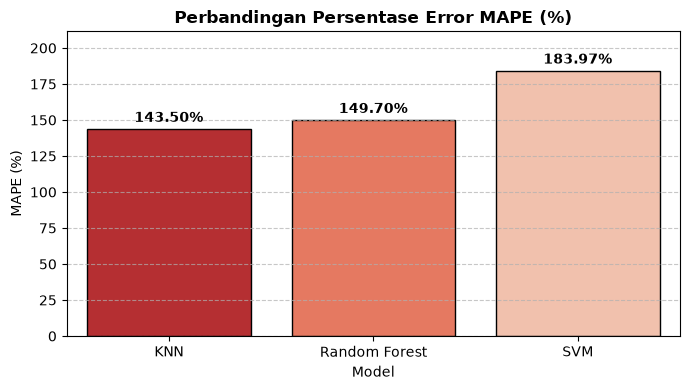

In [11]:
df_urut_mape = df_perbandingan.sort_values(by='MAPE (%)', ascending=True)

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    data=df_urut_mape, x='Model', y='MAPE (%)', 
    hue='Model', palette='Reds_r', edgecolor='black', legend=False
)

plt.title('Perbandingan Persentase Error MAPE (%)', fontsize=12, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('MAPE (%)')
plt.ylim(0, df_urut_mape['MAPE (%)'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

### Visualisasi Perbandingan Waktu Eksekusi (Detik)

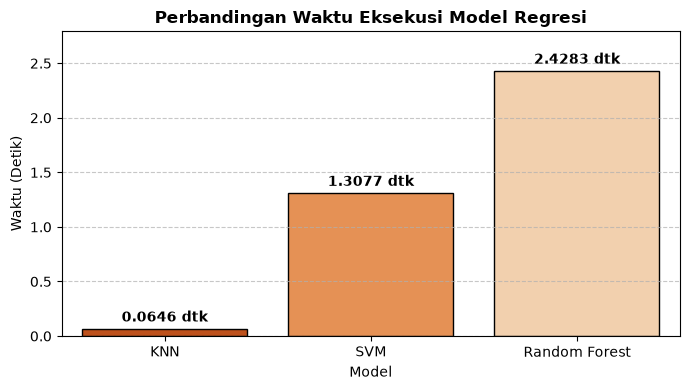

In [12]:
df_urut_waktu = df_perbandingan.sort_values(by='Waktu Eksekusi (Detik)', ascending=True)

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    data=df_urut_waktu, x='Model', y='Waktu Eksekusi (Detik)', 
    hue='Model', palette='Oranges_r', edgecolor='black', legend=False
)

plt.title('Perbandingan Waktu Eksekusi Model Regresi', fontsize=12, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Waktu (Detik)')
plt.ylim(0, df_urut_waktu['Waktu Eksekusi (Detik)'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='%.4f dtk', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

### Visualisasi Scatter Plot Harga Aktual vs Prediksi

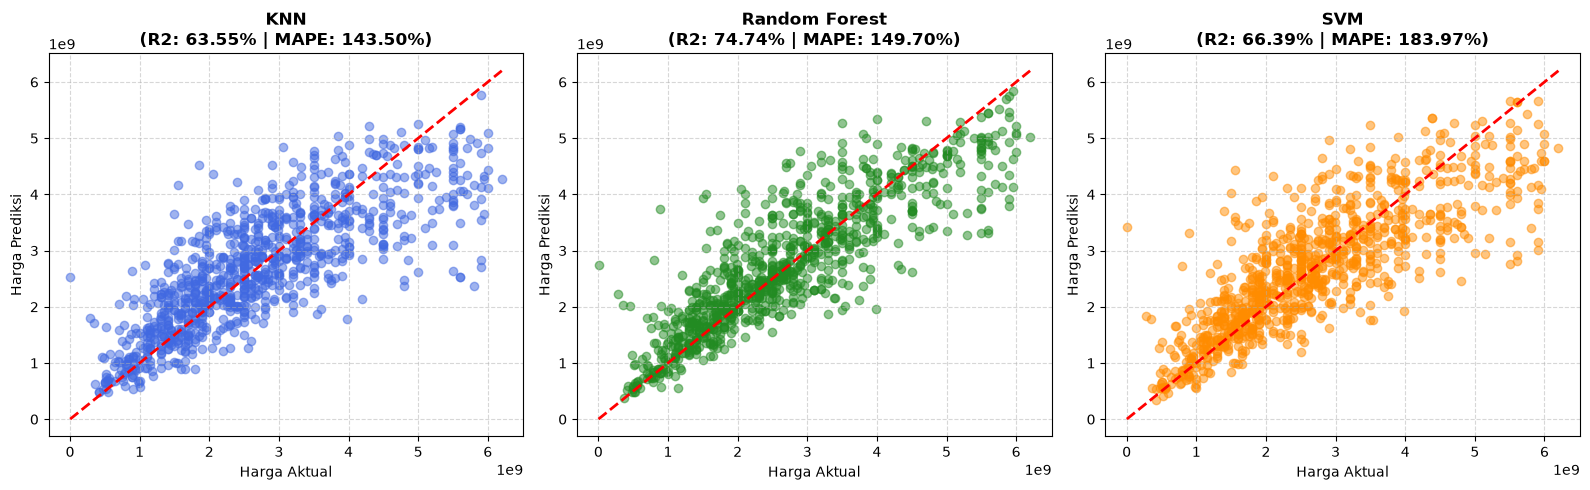

In [13]:
# Memuat hasil prediksi masing-masing model dari folder regresi_model/
hasil_knn = joblib.load('../regresi_model/hasil_knn.pkl')
hasil_rf  = joblib.load('../regresi_model/hasil_rf.pkl')
hasil_svm = joblib.load('../regresi_model/hasil_svm.pkl')

daftar_model = [hasil_knn, hasil_rf, hasil_svm]
warna_titik  = ['royalblue', 'forestgreen', 'darkorange']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, h in enumerate(daftar_model):
    y_test_m = h['y_test']
    y_pred_m = h['y_pred']
    
    axes[i].scatter(y_test_m, y_pred_m, alpha=0.5, color=warna_titik[i])
    axes[i].plot(
        [y_test_m.min(), y_test_m.max()],
        [y_test_m.min(), y_test_m.max()],
        'r--', linewidth=2
    )
    axes[i].set_title(f"{h['Model']}\n(R2: {h['R2']*100:.2f}% | MAPE: {h['MAPE (%)']:.2f}%)", fontweight='bold')
    axes[i].set_xlabel('Harga Aktual')
    axes[i].set_ylabel('Harga Prediksi')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()